# XGBoost on the Cleaned Full Dataset: Next-Game Points

This notebook trains **XGBoost** regressors to predict a player's points in a game (`target_pts`) from `data/NBA_player_stats_cleaned.csv`, the output of `ml/EDA/data_cleaning.ipynb`.

**Leakage rule:** every feature is built from games *before* the row's game. Same-game box-score values appear only in `target_*` columns, and none of those are used as features.

**Split:** the dataset's own `split` column.

| split | seasons | used for |
|---|---|---|
| train | 2021-22, 2022-23, 2023-24 | fitting every candidate model |
| val | 2024-25 | hyperparameter tuning and early stopping |
| test | 2025-26 | one final evaluation |

**Plan:** (1) random-search many hyperparameter configurations, fitting each on train and scoring on val; (2) plot every configuration as an interactive Lets-Plot scatter (MAE vs R², hover for the hyperparameters); (3) refit the best configuration on train + val; (4) score it once on test.

## Config

- `POINTS_DATA_PATH` (environment variable): use a different CSV. Default is the cleaned dataset.
- `N_CONFIGS`: how many random hyperparameter configurations to try.
- `PARAM_DISTRIBUTIONS`: the values each hyperparameter is sampled from.
- `MAX_ESTIMATORS` / `EARLY_STOPPING_ROUNDS`: boosting stops once val MAE has not improved for this many rounds.
- `SAVE_PLOT`: write the interactive plot to a standalone HTML file. Off by default.
- `SAVE_MODEL`: off by default, so running the notebook does not write artifacts or touch `ml/models/registry.json`.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost
from lets_plot import *
from sklearn.model_selection import ParameterSampler
from xgboost import XGBRegressor

LetsPlot.setup_html()

# Make the repo root importable so shared project code can be used here.
REPO_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents) if (root / 'data' / 'processing' / 'full_features.py').exists()),
    None,
)
assert REPO_ROOT is not None, 'Could not find the repo root (data/processing/full_features.py)'
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from data.processing import full_features
from ml.training.evaluation import regression_metrics

DATA_PATH = Path(os.environ.get('POINTS_DATA_PATH', REPO_ROOT / 'data' / 'NBA_player_stats_cleaned.csv'))
assert DATA_PATH.exists(), f'Could not find {DATA_PATH}'

TARGET = 'target_pts'
BASELINES = {
    'Season avg': 'pts_season_avg',
    'Last 5 avg': 'pts_last5_avg',
    'Last 10 avg': 'pts_last10_avg',
    'EWM': 'pts_ewm',
}

RANDOM_STATE = 42
MAX_ESTIMATORS = 2000
EARLY_STOPPING_ROUNDS = 100
N_CONFIGS = 40
PARAM_DISTRIBUTIONS = {
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'min_child_weight': [1, 5, 10, 20, 50],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.5, 0.7, 1.0],
    'reg_lambda': [0, 1, 5, 10],
    'gamma': [0, 0.5, 1],
}

SAVE_PLOT = True
PLOT_PATH = REPO_ROOT / 'ml' / 'training' / 'plots' / 'xgb_tuning.html'
SAVE_MODEL = True
MODEL_NAME = 'xgboost-points-full-cleaned'

print(DATA_PATH)
print('xgboost', xgboost.__version__)

/Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/data/NBA_player_stats_cleaned.csv
xgboost 3.4.1


## Load the dataset and prepare features

- `FEATURES` is every column that is not an identity column and not a `target_*` column.
- Boolean features become 0/1. `position` and `pos_group` become pandas categories, which XGBoost splits on directly (`enable_categorical=True`). Categories are set on the whole table so every split uses the same codes.
- Missing values stay as NaN. They mostly mean the player has no history yet, and XGBoost learns which branch to send them down.

In [2]:
df = pd.read_csv(DATA_PATH, dtype={'game_id': str})
df['game_date'] = pd.to_datetime(df['game_date'], format='%Y-%m-%d')

FEATURES = full_features.feature_columns(df.columns)
assert not any(c.startswith('target_') for c in FEATURES), 'A same-game target leaked into FEATURES'
assert set(df['split'].dropna()) == {'train', 'val', 'test'}, df['split'].unique()
assert df[TARGET].notna().all(), 'Rows without a target'

BOOL_STRINGS = {True: 1, False: 0, 'True': 1, 'False': 0}
CATEGORICAL = []
for column in FEATURES:
    values = df[column]
    if values.dtype == bool:
        df[column] = values.astype(int)
    elif pd.api.types.is_object_dtype(values) or pd.api.types.is_string_dtype(values):
        if set(values.dropna().unique()) <= set(BOOL_STRINGS):
            df[column] = values.map(BOOL_STRINGS).astype(float)
        else:
            df[column] = values.astype('category')
            CATEGORICAL.append(column)

train = df[df['split'] == 'train']
val = df[df['split'] == 'val']
test = df[df['split'] == 'test']
train_val = df[df['split'].isin(['train', 'val'])]

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]

print(f'{len(FEATURES)} features; categorical: {CATEGORICAL}')
pd.DataFrame({
    name: {
        'rows': len(frame),
        'players': frame['player_id'].nunique(),
        'first_game': frame['game_date'].min().date(),
        'last_game': frame['game_date'].max().date(),
        'mean_pts': round(frame[TARGET].mean(), 2),
    }
    for name, frame in [('train', train), ('val', val), ('test', test)]
}).T

64 features; categorical: ['position', 'pos_group']


,rows,players,first_game,last_game,mean_pts
train,78056,818,2021-10-19,2024-04-14,10.7
val,26206,569,2024-10-22,2025-04-13,10.68
test,26540,582,2025-10-21,2026-04-12,10.71


## Baselines

Each baseline predicts the target with one prior-only feature. They are scored on the rows where **every** baseline has a value (`common` rows), so all of them, and later the model, see the same games.

In [3]:
def common_rows(frame):
    return frame.dropna(subset=list(BASELINES.values()))


def score_rows(frame, predictions):
    """Baselines plus any named prediction Series, all on exactly `frame`'s rows."""
    scores = {name: regression_metrics(frame[TARGET], frame[column]) for name, column in BASELINES.items()}
    for name, pred in predictions.items():
        scores[name] = regression_metrics(frame[TARGET], pred.loc[frame.index])
    return pd.DataFrame(scores).T


val_common, test_common = common_rows(val), common_rows(test)
print(f'val: {len(val_common):,}/{len(val):,} common rows; test: {len(test_common):,}/{len(test):,}')
score_rows(val_common, {}).sort_values('MAE')

val: 25,638/26,206 common rows; test: 25,963/26,540


,n,MAE,RMSE,R2
EWM,25638.0,4.652,6.121,0.516
Season avg,25638.0,4.690,6.197,0.504
Last 10 avg,25638.0,4.713,6.190,0.505
Last 5 avg,25638.0,4.831,6.375,0.475


## Hyperparameter tuning (fit on train, scored on val)

`N_CONFIGS` configurations are sampled at random from `PARAM_DISTRIBUTIONS`. Each is fit on **train** with up to `MAX_ESTIMATORS` trees and early-stopped on val MAE; the best iteration is recorded as `n_trees`. Val MAE, RMSE and R² are computed on **all** val rows. Early stopping looks at the same val rows it is scored on, so val scores are slightly optimistic. Test is not touched here.

- `max_depth`: how deep each tree can grow.
- `learning_rate`: how much each new tree contributes.
- `min_child_weight`: the minimum amount of data in a leaf; larger values make trees more conservative.
- `subsample` / `colsample_bytree`: share of rows / features sampled per tree.
- `reg_lambda`: L2 penalty on leaf weights.
- `gamma`: minimum loss reduction needed to make a split.

In [4]:
def make_xgb(**params):
    return XGBRegressor(
        objective='reg:squarederror',
        tree_method='hist',
        enable_categorical=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **params,
    )


configs = list(ParameterSampler(PARAM_DISTRIBUTIONS, n_iter=N_CONFIGS, random_state=RANDOM_STATE))
tuning_rows = []
for i, params in enumerate(configs):
    candidate = make_xgb(n_estimators=MAX_ESTIMATORS, early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                         eval_metric='mae', **params)
    candidate.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    val_scores = regression_metrics(y_val, candidate.predict(X_val))
    train_scores = regression_metrics(y_train, candidate.predict(X_train))
    tuning_rows.append({'candidate': i, **params, 'n_trees': candidate.best_iteration + 1,
                        'MAE': val_scores['MAE'], 'RMSE': val_scores['RMSE'], 'R2': val_scores['R2'],
                        'train_MAE': train_scores['MAE']})
    print(f'[{i + 1}/{N_CONFIGS}] {params} -> val MAE {val_scores["MAE"]:.3f}, R2 {val_scores["R2"]:.3f}, '
          f'{candidate.best_iteration + 1} trees')

tuning = pd.DataFrame(tuning_rows).sort_values('MAE').reset_index(drop=True)
best_row = tuning.iloc[0]
best_params = {k: configs[int(best_row['candidate'])][k] for k in PARAM_DISTRIBUTIONS}
best_n_trees = int(best_row['n_trees'])
print(f'\nBest: {best_params}, {best_n_trees} trees, val MAE {best_row["MAE"]:.3f}, val R2 {best_row["R2"]:.3f}')
tuning.head(10)

[1/40] {'subsample': 0.8, 'reg_lambda': 10, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 1.0} -> val MAE 4.484, R2 0.556, 1352 trees
[2/40] {'subsample': 1.0, 'reg_lambda': 5, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.5} -> val MAE 4.512, R2 0.552, 125 trees
[3/40] {'subsample': 1.0, 'reg_lambda': 0, 'min_child_weight': 50, 'max_depth': 8, 'learning_rate': 0.03, 'gamma': 0.5, 'colsample_bytree': 0.7} -> val MAE 4.508, R2 0.552, 248 trees
[4/40] {'subsample': 0.8, 'reg_lambda': 5, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.5, 'colsample_bytree': 0.7} -> val MAE 4.482, R2 0.555, 572 trees
[5/40] {'subsample': 0.8, 'reg_lambda': 10, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0.5, 'colsample_bytree': 0.7} -> val MAE 4.485, R2 0.555, 160 trees
[6/40] {'subsample': 0.8, 'reg_lambda': 0, 'min_child_weight': 10, 'max_depth': 8, 'learn

,candidate,subsample,reg_lambda,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,n_trees,MAE,RMSE,R2,train_MAE
0,31,0.8,10,10,3,0.03,1.0,0.5,815,4.476,5.856,0.556,4.381
1,21,0.6,0,20,4,0.03,1.0,0.7,465,4.476,5.855,0.556,4.353
2,19,0.8,5,50,3,0.10,0.0,0.7,274,4.477,5.869,0.554,4.374
3,36,0.8,5,1,4,0.01,0.5,0.5,1506,4.478,5.856,0.556,4.347
4,25,0.8,0,50,3,0.05,0.0,1.0,382,4.478,5.860,0.556,4.394
5,13,0.8,0,50,3,0.10,1.0,0.7,216,4.478,5.864,0.555,4.390
6,27,1.0,10,20,3,0.03,1.0,0.5,940,4.479,5.864,0.555,4.373
7,14,0.6,10,10,3,0.01,1.0,0.5,2000,4.479,5.854,0.557,4.394
8,6,0.8,10,20,5,0.03,0.0,0.5,373,4.481,5.856,0.556,4.305
9,37,0.8,1,10,3,0.03,0.5,0.5,566,4.482,5.868,0.554,4.403


## Interactive tuning graph (Lets-Plot)

Every tried configuration is one dot: **MAE on the x-axis** (lower is better) and **R² on the y-axis** (higher is better), so the best models sit in the top-left corner. Hover over a dot to see that configuration's hyperparameters, tree count and metrics. Dots are colored by `max_depth`; the best configuration (lowest val MAE) is the large red-outlined dot.

In [5]:
tuning_plot = tuning.copy()
tuning_plot['config'] = tuning_plot['candidate'].astype(int)
tuning_plot['is_best'] = False
tuning_plot.loc[0, 'is_best'] = True

point_tooltips = (
    layer_tooltips()
    .title('Config #@config')
    .line('Val MAE|@MAE')
    .line('Val R²|@R2')
    .line('Val RMSE|@RMSE')
    .line('Train MAE|@train_MAE')
    .line('n_trees|@n_trees')
    .line('max_depth|@max_depth')
    .line('learning_rate|@learning_rate')
    .line('min_child_weight|@min_child_weight')
    .line('subsample|@subsample')
    .line('colsample_bytree|@colsample_bytree')
    .line('reg_lambda|@reg_lambda')
    .line('gamma|@gamma')
)

tuning_graph = (
    ggplot(tuning_plot, aes('MAE', 'R2'))
    + geom_point(aes(color=as_discrete('max_depth')), size=5, alpha=0.85, tooltips=point_tooltips)
    + geom_point(data=tuning_plot[tuning_plot['is_best']], shape=1, size=9, stroke=2, color='red',
                 tooltips=point_tooltips)
    + scale_color_brewer(name='max_depth', palette='Set1')
    + labs(title=f'XGBoost hyperparameter search: {N_CONFIGS} configurations (validation set, 2024-25)',
           subtitle='Hover a dot for its hyperparameters. Best models are top-left (low MAE, high R²).',
           x='Validation MAE (points)', y='Validation R²')
    + theme_minimal()
    + ggsize(950, 600)
)
tuning_graph

In [6]:
# Optional: save the interactive plot as a standalone HTML file you can open in any browser.
if SAVE_PLOT:
    PLOT_PATH.parent.mkdir(parents=True, exist_ok=True)
    ggsave(tuning_graph, PLOT_PATH.name, path=str(PLOT_PATH.parent))
    print('Saved', PLOT_PATH)
else:
    print('SAVE_PLOT is False; nothing written.')

Saved /Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/ml/training/plots/xgb_tuning.html


## Train the final model on train + val

The final model is refit on train + val with the best hyperparameters. There is no early-stopping set left, so the tree count is the best val iteration scaled up by how much more data the refit has. This is a common rule of thumb, not a tuned value.

In [7]:
final_n_estimators = max(1, round(best_n_trees * len(train_val) / len(train)))
final_params = {**best_params, 'n_estimators': final_n_estimators}
X_train_val, y_train_val = train_val[FEATURES], train_val[TARGET]
model = make_xgb(**final_params).fit(X_train_val, y_train_val)
print(f'Final model: {final_params}')

Final model: {'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 10, 'subsample': 0.8, 'colsample_bytree': 0.5, 'reg_lambda': 10, 'gamma': 1, 'n_estimators': 1089}


## Evaluate on test (2025-26)

This is the only time test is used. The model and every baseline are scored on the same common rows. The breakdown then repeats the model's score on subsets:

- **all test rows:** includes players with no history, where the baselines are NaN.
- **≥ 5 prior games** (`insufficient_history == 0`)
- **rotation players** (`low_minutes_prior == 0`)

In [8]:
test_pred = pd.Series(model.predict(test[FEATURES]), index=test.index)

test_scores = score_rows(test_common, {'XGBoost': test_pred})
best_baseline = test_scores.drop(index='XGBoost')['MAE'].idxmin()
beats = test_scores.loc['XGBoost', 'MAE'] < test_scores.loc[best_baseline, 'MAE']
print(f'Best baseline: {best_baseline} -> XGBoost beats it: {beats}')
test_scores.sort_values('MAE')

Best baseline: EWM -> XGBoost beats it: True


,n,MAE,RMSE,R2
XGBoost,25963.0,4.463,5.810,0.547
EWM,25963.0,4.625,6.073,0.505
Last 10 avg,25963.0,4.676,6.142,0.494
Season avg,25963.0,4.687,6.189,0.486
Last 5 avg,25963.0,4.801,6.310,0.466


In [9]:
subsets = {
    'all test rows': test,
    'common rows': test_common,
    '>= 5 prior games': test[test['insufficient_history'] == 0],
    'rotation players': test[test['low_minutes_prior'] == 0],
}
pd.DataFrame({name: regression_metrics(rows[TARGET], test_pred.loc[rows.index])
              for name, rows in subsets.items() if len(rows)}).T

,n,MAE,RMSE,R2
all test rows,26540.0,4.458,5.812,0.548
common rows,25963.0,4.463,5.810,0.547
>= 5 prior games,26035.0,4.479,5.832,0.546
rotation players,23843.0,4.658,6.010,0.512


## Diagnostics

- **Feature importance (gain):** how much each feature's splits reduced the loss on average. The top 25 are shown.
- **Predicted vs actual:** points on the diagonal are perfect predictions.
- **Error by expected minutes:** MAE grouped by `min_ewm`, the player's recent minutes.
- **Residuals by player:** players whose test games the model gets most wrong.

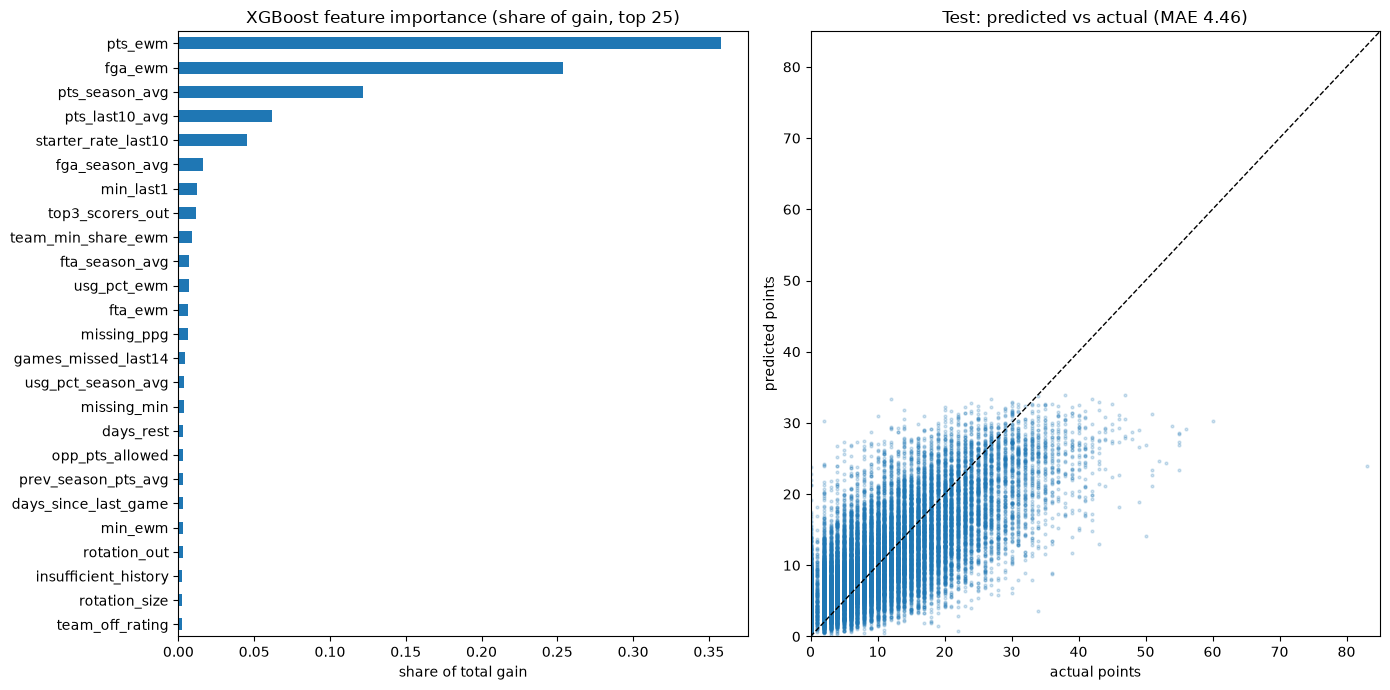

In [10]:
importance = pd.Series(model.get_booster().get_score(importance_type='gain')).reindex(FEATURES).fillna(0)
importance = importance / importance.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
importance.sort_values().tail(25).plot.barh(ax=axes[0], color='tab:blue')
axes[0].set_title('XGBoost feature importance (share of gain, top 25)')
axes[0].set_xlabel('share of total gain')

lim = [0, max(test[TARGET].max(), test_pred.max()) + 2]
axes[1].scatter(test[TARGET], test_pred, s=4, alpha=0.2)
axes[1].plot(lim, lim, 'k--', linewidth=1)
axes[1].set(xlim=lim, ylim=lim, xlabel='actual points', ylabel='predicted points',
            title=f"Test: predicted vs actual (MAE {regression_metrics(test[TARGET], test_pred)['MAE']:.2f})")
plt.tight_layout()
plt.show()

In [11]:
residuals = test.assign(predicted=test_pred, error=test_pred - test[TARGET],
                        abs_error=(test_pred - test[TARGET]).abs())
minutes_bucket = pd.cut(residuals['min_ewm'], [0, 10, 20, 30, 40, 60], right=False)
(residuals.groupby(minutes_bucket.cat.add_categories('no history').fillna('no history'), observed=True)
 .agg(rows=('error', 'size'), MAE=('abs_error', 'mean'), bias=('error', 'mean'), avg_points=(TARGET, 'mean'))
 .round(2))

,rows,MAE,bias,avg_points
min_ewm,,,,
"[0, 10)",2697,2.68,0.03,3.11
"[10, 20)",7354,3.74,0.14,6.03
"[20, 30)",10578,4.71,0.15,11.37
"[30, 40)",5797,5.75,0.28,19.08
"[40, 60)",12,4.70,-1.14,24.75
no history,102,3.01,-0.55,3.80


In [12]:
by_player = (residuals.groupby('player_name')
             .agg(games=('error', 'size'), MAE=('abs_error', 'mean'), bias=('error', 'mean'),
                  avg_points=(TARGET, 'mean'))
             .query('games >= 10')
             .sort_values('MAE', ascending=False)
             .round(2))
print('Players with the largest test error (bias > 0 means over-predicted):')
by_player.head(10)

Players with the largest test error (bias > 0 means over-predicted):


,games,MAE,bias,avg_points
player_name,,,,
Max Strus,12,8.48,-0.48,11.17
Anthony Edwards,61,8.43,-1.57,28.80
Cam Thomas,42,8.02,4.09,13.50
Stephen Curry,43,7.95,-0.34,26.56
Jamal Murray,75,7.66,-0.89,25.40
Keyonte George,54,7.52,-1.00,23.61
Anthony Davis,20,7.48,1.48,20.35
Luka Doncic,64,7.43,-2.47,33.48
Ja Morant,20,7.35,2.97,19.45


## Save the model (optional)

When `SAVE_MODEL = True`, this calls `ml.model_integrity.save_model`, the same as `train_tree_points.py` and `XGBoost.ipynb`. It writes the artifact, its manifest (with the config and metrics above) and a `candidate` entry in `ml/models/registry.json`. It is off by default.

In [13]:
if SAVE_MODEL:
    from ml.model_integrity import save_model, sha256_file

    training_config = {
        'training_script': 'ml/training/XGBoost_full_dataset.ipynb',
        'feature_builder': 'data/processing/full_features.py',
        'estimator': 'XGBRegressor(objective=reg:squarederror, tree_method=hist, enable_categorical=True)',
        'xgboost_params': {**final_params, 'random_state': RANDOM_STATE},
        'tuning': {'search': 'random', 'n_configs': N_CONFIGS, 'param_distributions': PARAM_DISTRIBUTIONS,
                   'early_stopping_rounds': EARLY_STOPPING_ROUNDS, 'best_val_n_trees': best_n_trees,
                   'selected_on': 'val'},
        'features': FEATURES,
        'categorical_features': CATEGORICAL,
        'target': TARGET,
        'split': {'fit': 'train + val (2021-22 to 2024-25)', 'tuning': 'val (2024-25)', 'test': 'test (2025-26)'},
        'dataset': str(DATA_PATH.relative_to(REPO_ROOT)) if DATA_PATH.is_relative_to(REPO_ROOT) else str(DATA_PATH),
        'dataset_sha256': sha256_file(DATA_PATH),
        'xgboost_version': xgboost.__version__,
    }
    evaluation_metrics = {
        'model': 'XGBoost',
        'val_tuning': tuning.iloc[0].to_dict(),
        'test': test_scores.loc['XGBoost'].to_dict(),
        'baselines_test': test_scores.drop(index='XGBoost').to_dict(orient='index'),
        'best_baseline': best_baseline,
        'beats_best_baseline': bool(beats),
        'test_all_rows': regression_metrics(test[TARGET], test_pred),
    }
    entry = save_model(model, model_name=MODEL_NAME, features=X_train_val, dataset_path=DATA_PATH,
                       training_config=training_config, evaluation_metrics=evaluation_metrics)
    print(json.dumps({'saved': entry['model_version'], 'artifact': entry['artifact_path']}, indent=2))
else:
    print('SAVE_MODEL is False; nothing written.')

{
  "saved": "xgboost-points-full-cleaned-v1+20261128T060013Z.694f4e0",
  "artifact": "artifacts/xgboost-points-full-cleaned_20261128T060013Z_694f4e0.joblib"
}
